# ДЗ: Поворин Георгий

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Задание 1

In [20]:
mu0, n, x_bar, sigma = 120, 100, 124, 25

se = sigma / np.sqrt(n)
z = (x_bar - mu0) / se #на сколько оценка ушла от 120
pvalue = 2 * stats.norm.sf(abs(z)) #ддвусторонний p-value

print("SE =", se)
print("z =", z)
print("p =", round(pvalue, 4))

SE = 2.5
z = 1.6
p = 0.1096


H₀: μ = 120

H₁: μ ≠ 120

порог при двустороннем тесте и a=5% равен 1,96

Поскольку 1,6 < 1,96 и p ≈ 0,11 > 0,05, то оснований отвергать $H_0$ нет

Важно: наши наблюдение не дакозывают, реально ли среднее = 120, просто нам не хватает данных, чтобы утверждать обратное

## Задание 2

In [21]:
n1, x1, s1 = 40, 50, 10
n2, x2, s2 = 40, 55, 10

diff = x2 - x1
v1, v2 = s1**2 / n1, s2**2 / n2
se = np.sqrt(v1 + v2)

# степени свободы Уэлча–Саттертуэйта
df = (v1 + v2)**2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))

t_crit = stats.t.ppf(0.975, df)
low = diff - t_crit * se
high = diff + t_crit * se

print("diff =", diff)
print("SE =", round(se, 3))
print("df =", round(df, 1))
print("t_crit =", round(t_crit, 3))
print("95% ДИ = [", round(low, 3), ", ", round(high, 3), "]", sep="")

diff = 5
SE = 2.236
df = 78.0
t_crit = 1.991
95% ДИ = [0.548, 9.452]


0 не попадает в интервал

самый маленький эффект = 0.548, ну то есть левая граница интервала

## Задание 3

In [22]:
x1, n1 = 90, 1000
x2, n2 = 120, 1000

p1, p2 = x1 / n1, x2 / n2
p_pool = (x1 + x2) / (n1 + n2)

diff = (p2 - p1) * 100
z = (p2 - p1) / np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
pvalue = 2 * stats.norm.sf(abs(z))

print("p1 =", round(p1, 3))
print("p2 =", round(p2, 3))
print("diff =", round(diff, 1), "п.п.")
print("z =", round(z, 3))
print("p =", round(pvalue, 4))

p1 = 0.09
p2 = 0.12
diff = 3.0 п.п.
z = 2.188
p = 0.0287


H₀: p₁ = p₂

H₁: p₁ ≠ p₂

z>1.96 и p< 0.05, а значит $H_0$ отвергаем

## Задание 4

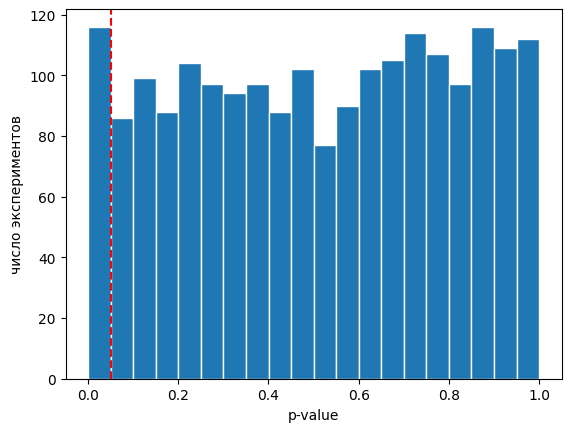


Доля p < 0.05: 0.057


In [23]:
rng = np.random.default_rng(7)

pvals = np.empty(2000)
for i in range(2000):
    control = rng.normal(0, 1, 200)
    test = rng.normal(0, 1, 200)
    pvals[i] = stats.ttest_ind(control, test, equal_var=False).pvalue

plt.hist(pvals, bins=20, edgecolor="white")
plt.axvline(0.05, color="red", ls="--")
plt.xlabel("p-value")
plt.ylabel("число экспериментов")
plt.show()

print()
print("Доля p < 0.05:", (pvals < 0.05).mean())

Гистограмма получается примерно плоской. Причина: при верной $H_0$ и непрерывном критерии p-value равномерно распределён на [0, 1]. Отсюда следует ошибка 1 рода: доля p < 0,05 около 5%. Плоская гистограмма также подтверждает, что тест корректно откалиброван, так как показывает примерное равенство столбиков

## Задание 5

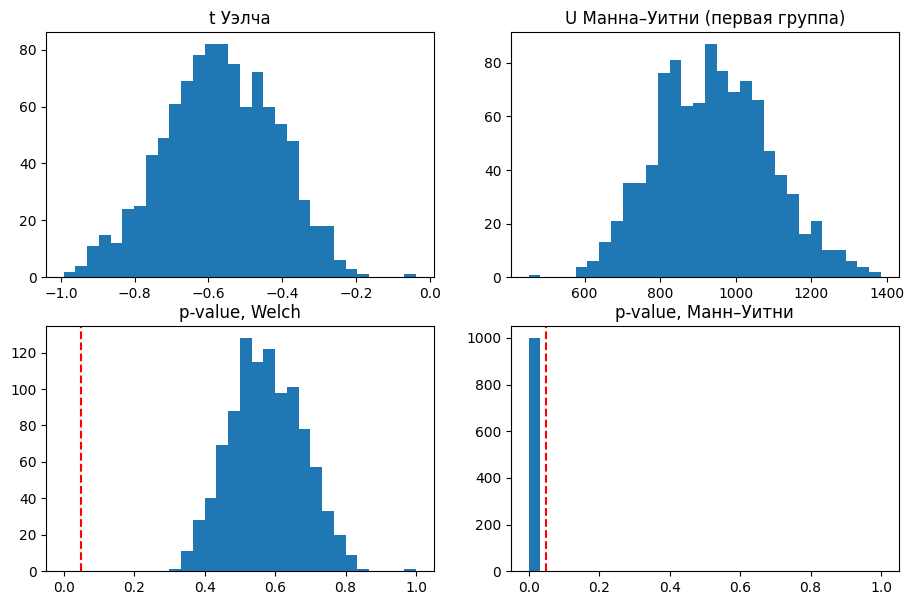


Средняя разница: -0.685999446205402
Welch отвергает H0: 0.0
Манн–Уитни отвергает H0: 1.0
Медиана p-value: 0.5703217627013764 6.366975944407124e-06


In [24]:
rng = np.random.default_rng(7)

diffs = []
t_stats = []
u_stats = []
p_t = []
p_u = []

for _ in range(1000):
    control = rng.normal(0, 1, 60)
    test = rng.normal(1, 1, 60)
    test[:2] = -50

    res_t = stats.ttest_ind(test, control, equal_var=False)
    res_u = stats.mannwhitneyu(control, test, alternative="two-sided")

    diffs.append(test.mean() - control.mean())
    t_stats.append(res_t.statistic)
    p_t.append(res_t.pvalue)
    u_stats.append(res_u.statistic)
    p_u.append(res_u.pvalue)

p_t = np.array(p_t)
p_u = np.array(p_u)

plt.figure(figsize=(11, 7))

plt.subplot(2, 2, 1)
plt.hist(t_stats, bins=30)
plt.title("t Уэлча")

plt.subplot(2, 2, 2)
plt.hist(u_stats, bins=30)
plt.title("U Манна–Уитни (первая группа)")

plt.subplot(2, 2, 3)
plt.hist(p_t, bins=30, range=(0, 1))
plt.axvline(0.05, color="red", ls="--")
plt.title("p-value, Welch")

plt.subplot(2, 2, 4)
plt.hist(p_u, bins=30, range=(0, 1))
plt.axvline(0.05, color="red", ls="--")
plt.title("p-value, Манн–Уитни")

plt.show()

print()
print("Средняя разница:", np.mean(diffs))
print("Welch отвергает H0:", (p_t < 0.05).mean())
print("Манн–Уитни отвергает H0:", (p_u < 0.05).mean())
print("Медиана p-value:", np.median(p_t), np.median(p_u))

- p-value Welch сосредоточены примерно в середине и тест ни рау не отвергает $H_0$

- Манн–Уитни смотрит только на ранги: оба выброса. Его p-value приплюснуты к нулю и в 100% случаев $H_0$ опровергается

Манн–Уитни обнаруживает реальный сдвиг распределения, а t-test его пропускает

Вывод стандартный: среднее неустойчиво к выбросам (ну тут конечно с оговорками, так как Манн-Уитни немного не про сравнение средних. Да и если в реальности для бизнеса где-либо важно именно среднее, то выбросы должны удалять из этого наализа и разбирать отдельно)

## Задание 6

In [25]:
rng = np.random.default_rng(7)
control = rng.normal(10, 2, 80)
test = rng.normal(10.8, 2.6, 75)

res = stats.ttest_ind(test, control, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)
diff = test.mean() - control.mean()

print("diff =", round(diff, 3))
print("t =", round(res.statistic, 3))
print("p =", round(res.pvalue, 4))
print("95% ДИ = [", round(ci.low, 3), ", ", round(ci.high, 3), "]", sep="")

diff = 0.757
t = 2.308
p = 0.0225
95% ДИ = [0.109, 1.404]


Разница средних 0,757, а p = 0,0225 < 0,05 => H₀ отвергаем

0 в интервал не попадает, а наименьший эффект = 0.109

## Задание 7

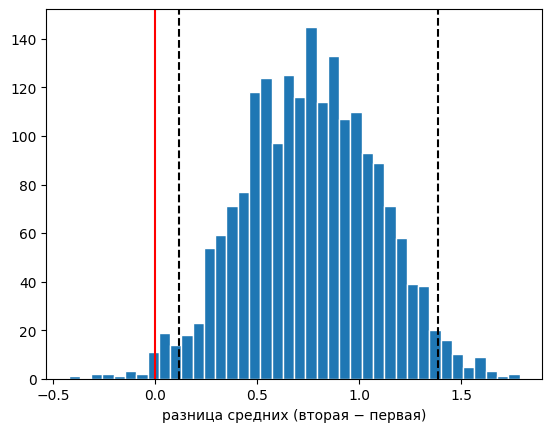

Бутстрап 95% ДИ: [0.117, 1.386]
Доля разниц <= 0: 0.0085


In [26]:
rng_boot = np.random.default_rng(42)
n_boot = 2000

boot_diffs = np.empty(n_boot)
for i in range(n_boot):
    s1 = rng_boot.choice(control, size=len(control), replace=True)
    s2 = rng_boot.choice(test, size=len(test), replace=True)
    boot_diffs[i] = s2.mean() - s1.mean()

low, high = np.percentile(boot_diffs, [2.5, 97.5])
share_le_0 = (boot_diffs <= 0).mean()

plt.hist(boot_diffs, bins=40, edgecolor="white")
plt.axvline(low, color="black", ls="--")
plt.axvline(high, color="black", ls="--")
plt.axvline(0, color="red")
plt.xlabel("разница средних (вторая − первая)")
plt.show()

print("Бутстрап 95% ДИ: [", round(low, 3), ", ", round(high, 3), "]", sep="")
print("Доля разниц <= 0:", round(share_le_0, 4))

Назвать её p-value в строгом смысле нельзя, по двум причинам:
- бутстрап центрирован на наблюдаемой разнице (около 0,75), а не на нуле, т.e. оно описывает неопределённость оценки, а не статистику при верной H₀
- такая доля односторонняя, а выбранный нами тест двусторонний, ччтобы получить настоящий p-value, нужно моделировать мир, где H₀ верна: к примеру сдвинуть обе группы к общему среднему перед пересэмплированием, и только потом считать долю не менее экстремальных значений, чем наблюдённая разница. Грубо удвоенная доля близка к
p = 0,0225 из Welch, но это лишь приближение

## Спасибо за дз и за проверку!